# Walk exploration (figures)

Synthetic plots from **precomputed walk caches**. Generate graphs and caches via `1_synthetic_walk_exploration_data_processing.ipynb`, then run the cells below.


In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RESULTS = Path("results") / "walk_exploration"
RESULTS.mkdir(parents=True, exist_ok=True)

RESULTS_IMAGES = Path("results") / "images"
RESULTS_IMAGES.mkdir(parents=True, exist_ok=True)


PQ_GRID_COV = [
    (0.25, 4), (0.5, 2), (1, 2), (1, 1), (0.5, 0.5), (2, 1),
    (2, 0.5), (4, 0.25)
]

GAMMAS = [-1.0, 1.0]
N_GRAPHS = 5

PQ_GRID_TRANS = [
    (0.25, 4), (0.5, 2), (1, 1), (0.5, 0.5),
    (2, 0.5), (4, 0.25)
]

GAMMA_COMM = -1.0
PQ_JOINT = [(0.25, 4), (1, 1), (4, 0.25)]


def load_pickle(p: Path):
    with open(p, "rb") as f:
        return pickle.load(f)


walk_5_cache_cov = load_pickle(RESULTS / "walk_cache_cov_ncom1_avgdeg5.pkl")
walk_20_cache_cov = load_pickle(RESULTS / "walk_cache_cov_ncom1_avgdeg20.pkl")

colors = plt.get_cmap("Set2").colors


### Coverage (p, q) × $\gamma$


In [ ]:
def plot_joint_pq_gamma_coverage(
    walk_cache,
    results_dir: Path,
    *,
    png_name: str,
    n_graphs: int = N_GRAPHS,
    legend: bool = True,
):
    metric_rows = [
        ("node", "Mean Unique Nodes Visited"),
        ("hyper", "Mean Unique Hyperedges Visited"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey="row")

    for row_idx, (metric_key, ylabel) in enumerate(metric_rows):
        for col_idx, gamma_val in enumerate(GAMMAS):
            ax = axes[row_idx, col_idx]
            for i, (p_i, q_i) in enumerate(PQ_GRID_COV[::-1]):
                curves = [walk_cache[(gamma_val, p_i, q_i, g)][metric_key] for g in range(n_graphs)]
                C = np.vstack(curves)
                mean_c, std_c = C.mean(axis=0), C.std(axis=0)
                steps = np.arange(1, len(mean_c) + 1)
                c = colors[i % len(colors)]
                ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
                ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.2)

            ax.grid(alpha=0.3)
            if row_idx == 1:
                ax.set_xlabel("Walk Step", fontsize=10)
            if col_idx == 0:
                ax.set_ylabel(ylabel, fontsize=10)

    # Mention gamma values once as column headers.
    fig.text(0.28, 0.98, rf"$\gamma={GAMMAS[0]:.0f}$", ha="center", va="top", fontsize=10)
    fig.text(0.73, 0.98, rf"$\gamma={GAMMAS[1]:.0f}$", ha="center", va="top", fontsize=10)

    if legend:
        axes[0, 1].legend(frameon=False, title="HARW Parameters", fontsize=6, title_fontsize=8)

    axes[0, 0].set_ylim(0.0, 101)
    axes[0, 1].set_ylim(0.0, 101)
    axes[1, 0].set_ylim(0.0, 101)
    axes[1, 1].set_ylim(0.0, 101)

    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(results_dir / png_name, dpi=300, bbox_inches="tight")
    plt.show()

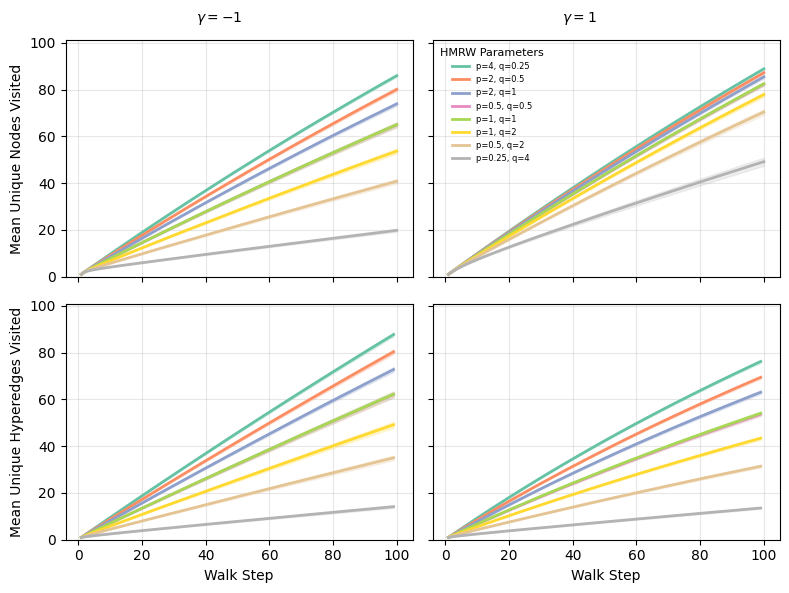

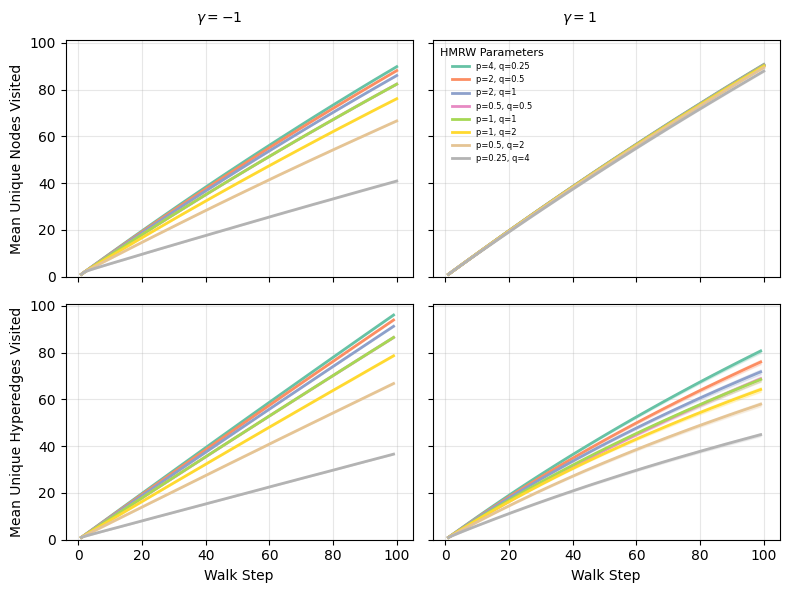

In [3]:
# Average degree 5
plot_joint_pq_gamma_coverage(
    walk_5_cache_cov,
    RESULTS_IMAGES,
    png_name="synth_coverage_sparse.png",
)

# Average degree 20
plot_joint_pq_gamma_coverage(
    walk_20_cache_cov,
    RESULTS_IMAGES,
    png_name="synth_coverage_dense.png",
)


### Stage-1 transition diagnostics


In [4]:
def plot_stage1_barplot_two_rows(
    walk_cache_top,
    walk_cache_bottom,
    results_dir: Path,
    *,
    row_labels=("Average degree 5", "Average degree 20"),
    png_name: str = "synth_transition_cases_joint_ncom1_avgdeg5_20.png",
    n_graphs: int = N_GRAPHS,
):
    gamma_diag = -1.0
    case_names = ["same hyperedge", "middle case", "other case"]
    group_labels = [f"p={p_i}, q={q_i}" for (p_i, q_i) in PQ_GRID_TRANS]
    case_colors = ["#66c2a5", "#fc8d62", "#8da0cb"]

    def compute_values(walk_cache):
        selected_vals = []
        possible_vals = []
        for p_i, q_i in PQ_GRID_TRANS:
            selected_curves = [walk_cache[(gamma_diag, p_i, q_i, g)]["case"] for g in range(n_graphs)]
            possible_curves = [walk_cache[(gamma_diag, p_i, q_i, g)]["possible"] for g in range(n_graphs)]
            selected_vals.append(np.stack(selected_curves, axis=0).mean(axis=(0, 1)))
            possible_vals.append(np.stack(possible_curves, axis=0).mean(axis=(0, 1)))
        return np.asarray(selected_vals), np.asarray(possible_vals)

    selected_top, possible_top = compute_values(walk_cache_top)
    selected_bottom, possible_bottom = compute_values(walk_cache_bottom)

    fig, axes = plt.subplots(2, 2, figsize=(8, 6.0), gridspec_kw={"width_ratios": [4, 1]}, sharey=True)
    x = np.arange(len(PQ_GRID_TRANS))
    bar_w = 0.26

    rows_data = [
        (selected_top, possible_top, row_labels[0]),
        (selected_bottom, possible_bottom, row_labels[1]),
    ]

    for r, (selected_vals, possible_vals, row_label) in enumerate(rows_data):
        # Left panel: Selection (same style as original)
        for j, name in enumerate(case_names):
            axes[r, 0].bar(x + (j - 1) * bar_w, selected_vals[:, j], width=bar_w, color=case_colors[j], label=name)
        axes[r, 0].set_ylim(0.0, 1.05)
        axes[r, 0].set_ylabel("Mean Fraction", fontsize=10)
        if r == 1:
            axes[r, 0].set_xlabel("Hyperparameter Set (p, q)", fontsize=10)
        if r == 0:
            axes[r, 0].set_title("Selection")
        else:
            axes[r, 0].set_title("")
        axes[r, 0].grid(axis="y", alpha=0.3)
        axes[r, 0].set_xticks(x)
        axes[r, 0].set_xticklabels(group_labels, rotation=20, ha="right", fontsize=7)
        if r == 0:
            axes[r, 0].tick_params(axis="x", which="both", bottom=False, labelbottom=False)

        # Right panel: Availability (single aggregated group, same as original)
        avail_one = possible_vals.mean(axis=0)
        x2 = np.array([0.0])
        for j, _ in enumerate(case_names):
            axes[r, 1].bar(x2 + (j - 1) * bar_w, [avail_one[j]], width=bar_w, color=case_colors[j])
        axes[r, 1].set_ylim(0.0, 1.05)
        if r == 0:
            axes[r, 1].set_title("Availability")
        else:
            axes[r, 1].set_title("")
        axes[r, 1].grid(axis="y", alpha=0.3)
        axes[r, 1].set_xticks([0.0])
        axes[r, 1].set_xticklabels(["all (p,q)"], fontsize=7)
        if r == 0:
            axes[r, 1].tick_params(axis="x", which="both", bottom=False, labelbottom=False)
        axes[r, 1].tick_params(axis="y", left=False, labelleft=False)

    # Single legend, matching original colors/cases.
    axes[0, 0].legend(frameon=False, loc="upper left", fontsize=7)

    fig.tight_layout()
    fig.subplots_adjust(hspace=0.04)
    fig.savefig(results_dir / png_name, dpi=300, bbox_inches="tight")
    plt.show()


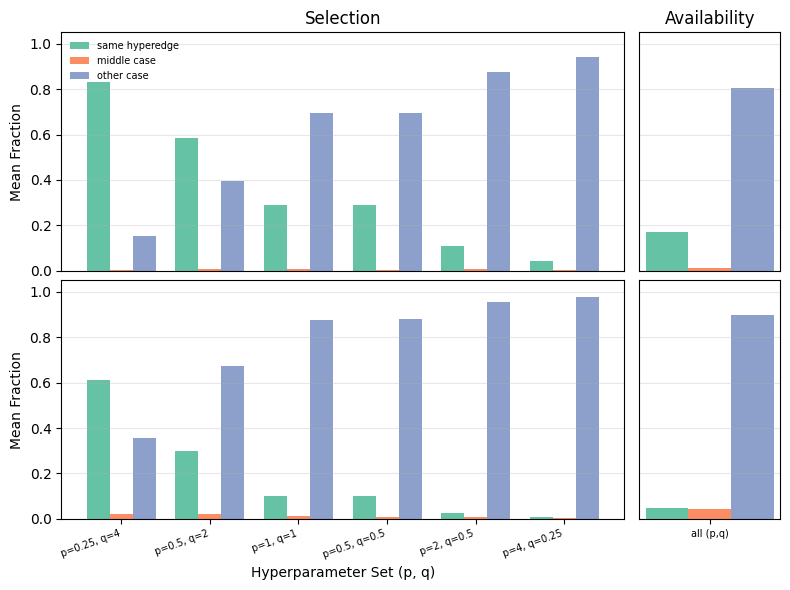

In [5]:
plot_stage1_barplot_two_rows(
    walk_5_cache_cov,
    walk_20_cache_cov,
    RESULTS_IMAGES,
    row_labels=("Average degree 5", "Average degree 20"),
    png_name="synth_transition_cases.png",
)


### Community mix (intra / (intra + inter))


In [6]:
def plot_joint_high_low_panel(ax, walk_cache_high, walk_cache_low, pq_joint: list, n_steps_plot: int):
    for i, (p_i, q_i) in enumerate(pq_joint):
        c = colors[i % len(colors)]
        key = (GAMMA_COMM, p_i, q_i)
        intra_h = [walk_cache_high[(*key, g)]["intra"][:n_steps_plot] for g in range(N_GRAPHS)]
        inter_h = [walk_cache_high[(*key, g)]["inter"][:n_steps_plot] for g in range(N_GRAPHS)]
        mean_intra_h = np.vstack(intra_h).mean(axis=0)
        mean_inter_h = np.vstack(inter_h).mean(axis=0)
        total_h = mean_intra_h + mean_inter_h
        ratio_h = np.divide(mean_intra_h, total_h, out=np.zeros_like(mean_intra_h), where=total_h > 0)
        intra_l = [walk_cache_low[(*key, g)]["intra"][:n_steps_plot] for g in range(N_GRAPHS)]
        inter_l = [walk_cache_low[(*key, g)]["inter"][:n_steps_plot] for g in range(N_GRAPHS)]
        mean_intra_l = np.vstack(intra_l).mean(axis=0)
        mean_inter_l = np.vstack(inter_l).mean(axis=0)
        total_l = mean_intra_l + mean_inter_l
        ratio_l = np.divide(mean_intra_l, total_l, out=np.zeros_like(mean_intra_l), where=total_l > 0)
        ax.plot(np.arange(len(ratio_h)), ratio_h, color=c, lw=2, linestyle="-")
        ax.plot(np.arange(len(ratio_l)), ratio_l, color=c, lw=2, linestyle="--")
    ax.set_xlabel("Walk Step")
    ax.set_ylim(0.4, 1.02)
    ax.grid(alpha=0.25)

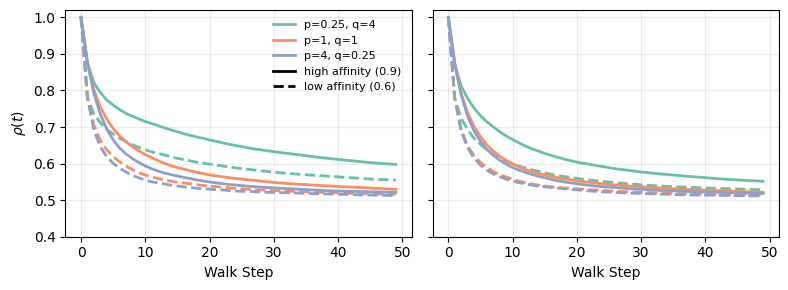

In [7]:
# Joint: avgdeg 5 vs 20 (two panels)
n_steps_plot = 50

w5h = load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg5_aff09.pkl")
w5l = load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg5_aff06.pkl")
w20h = load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg20_aff09.pkl")
w20l = load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg20_aff06.pkl")

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
plot_joint_high_low_panel(axes[0], w5h, w5l, PQ_JOINT, n_steps_plot)
axes[0].set_ylabel(r"$\rho(t)$", fontsize=10)
plot_joint_high_low_panel(axes[1], w20h, w20l, PQ_JOINT, n_steps_plot)

color_handles = [
    Line2D([0], [0], color=colors[i % len(colors)], lw=2, linestyle="-", label=f"p={p_i}, q={q_i}")
    for i, (p_i, q_i) in enumerate(PQ_JOINT)
]
style_handles = [
    Line2D([0], [0], color="black", lw=2, linestyle="-", label="high affinity (0.9)"),
    Line2D([0], [0], color="black", lw=2, linestyle="--", label="low affinity (0.6)"),
]
combined_handles = color_handles + style_handles
axes[0].legend(
    handles=combined_handles,
    frameon=False,
    fontsize=8,
    loc="upper right",
)
fig.tight_layout()
fig.savefig(RESULTS_IMAGES / "synth_community.png", dpi=300, bbox_inches="tight")
plt.show()


In [8]:
# (intentionally left blank)


### Hypergraph structure (ncom = 1)

Node degrees use `H.degree_distribution()` (mapping degree → count; expanded per graph for histograms). Hyperedge sizes use `H.get_sizes()`. For **average degree 5** and **average degree 20**, each row has two histograms: **mean of per-graph normalized densities** over all synthetic graphs (shared integer bins). Loads `hypergraphs_ncom1_avgdeg5.pkl` and `hypergraphs_ncom1_avgdeg20.pkl` from `1_synthetic_walk_exploration_data_processing.ipynb`.

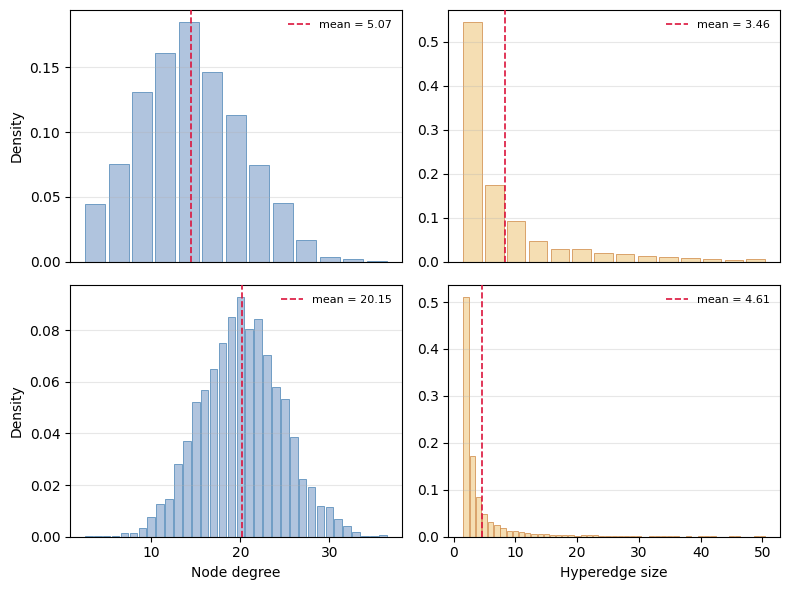

In [9]:
Hs_ncom1_deg5 = load_pickle(RESULTS / "hypergraphs_ncom1_avgdeg5.pkl")
Hs_ncom1_deg20 = load_pickle(RESULTS / "hypergraphs_ncom1_avgdeg20.pkl")

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
rows_data = [
    (Hs_ncom1_deg5, "Average degree 5"),
    (Hs_ncom1_deg20, "Average degree 20"),
]

for row, (Hs, row_title) in enumerate(rows_data):
    deg_samples = [
        np.array([d for d, c in H.degree_distribution().items() for _ in range(int(c))])
        for H in Hs
    ]
    size_samples = [np.asarray(H.get_sizes(), dtype=float) for H in Hs]

    for col, (samples_per_graph, color, edgecolor, xlabel) in enumerate([
        (deg_samples, "lightsteelblue", "steelblue", "Node degree"),
        (size_samples, "wheat", "peru", "Hyperedge size"),
    ]):
        ax = axes[row, col]

        pooled = np.concatenate(samples_per_graph)
        v_min, v_max = int(pooled.min()), int(pooled.max())
        bins = np.arange(v_min - 0.5, v_max + 1.5, 1.0)
        hists = [np.histogram(s, bins=bins, density=True)[0] for s in samples_per_graph]
        mean_h = np.mean(hists, axis=0)
        centers = (bins[:-1] + bins[1:]) / 2

        ax.bar(centers, mean_h, width=0.85, color=color, edgecolor=edgecolor, linewidth=0.5)
        mu = float(np.mean(pooled))
        ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, zorder=3, label=f"mean = {mu:.2f}")
        ax.legend(frameon=False, fontsize=8, loc="best")
        if col == 0:
            ax.set_ylabel("Density", fontsize=10)
        else:
            ax.set_ylabel("")
        if row == 1:
            ax.set_xlabel(xlabel, fontsize=10)
        else:
            ax.set_xlabel("")
            ax.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
        ax.grid(axis="y", alpha=0.3)

axes[0, 0].locator_params(axis="y", nbins=4)

fig.tight_layout()
fig.savefig(RESULTS_IMAGES / "synth_hypergraph_structure.png", dpi=300, bbox_inches="tight")
plt.show()
